# 문제 5: 고정 MobileNetV2 특징 + 규제 로지스틱 회귀
시작: 2026-10-01 17:48 KST, 마감 18:18 KST. 구현 승인 시점에 약 1분 20초만 남아 기준 모델만 실행한다. 추가 모델 비교와 색상·질감 보완은 미실행이다. 개발 600장 3-fold OOF, 확인 150장 1회 평가 후 전체 750장으로 학습한다.

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


label
0    150
1    150
2    150
3    150
4    150
Name: train_count, dtype: int64

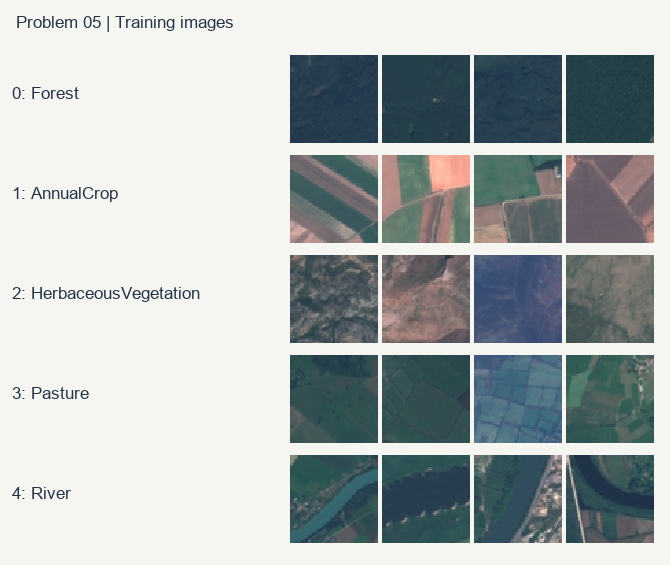

development / holdout: 600 150 execution started: 2026-10-01T18:17:47.148122+09:00


In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS']='2'
os.environ['OMP_NUM_THREADS']='2'
import time, json, warnings
from datetime import datetime
from zoneinfo import ZoneInfo
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from threadpoolctl import threadpool_limits
from feature_helper import extract_features
thread_limit = threadpool_limits(limits=2)
t0=time.perf_counter()
started=datetime.now(ZoneInfo('Asia/Seoul')).isoformat()
labels=[0,1,2,3,4]
train=pd.read_csv('data/train.csv'); test=pd.read_csv('data/test.csv'); sample=pd.read_csv('data/sample_submission.csv')
assert len(train)==750 and len(test)==250
assert train.image_id.is_unique and test.image_id.is_unique
assert not set(train.image_id)&set(test.image_id)
assert not train.isna().any().any() and not test.isna().any().any()
assert train.label.isin(labels).all()
y=train.label.to_numpy()
dev,hold=train_test_split(np.arange(len(train)),test_size=0.2,stratify=y,random_state=42)
assert not set(dev)&set(hold)
display(train.label.value_counts().sort_index().rename('train_count'))
display(Image.open('training_examples.png'))
print('development / holdout:',len(dev),len(hold),'execution started:',started)


In [2]:
feature_start=time.perf_counter()
X=extract_features(train.image_path.tolist(),cache_path='train_features.npz')
Xt=extract_features(test.image_path.tolist(),cache_path='test_features.npz')
assert X.shape==(750,1280) and Xt.shape==(250,1280)
assert np.isfinite(X).all() and np.isfinite(Xt).all()
feature_seconds=time.perf_counter()-feature_start
print('Feature extraction seconds:',feature_seconds)


2026-10-01 18:17:47.278601053 [W:onnxruntime:Default, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


Images processed: 100/750


Images processed: 200/750


Images processed: 300/750


Images processed: 400/750


...

Images processed: 700/750


Images processed: 750/750


Images processed: 100/250


Images processed: 200/250


Images processed: 250/250
Feature extraction seconds: 7.818506456999785


In [3]:
def make_model():
    return make_pipeline(StandardScaler(),Normalizer(norm='l2'),
                         LogisticRegression(C=1,solver='lbfgs',max_iter=2000))
def macro(a,b):
    return float(f1_score(a,b,labels=labels,average='macro',zero_division=0))
cv_start=time.perf_counter()
oof=np.full(len(dev),-1,dtype=int)
fold_scores=[]; fold_class_f1=[]; warning_messages=[]
for fold,(tr,va) in enumerate(StratifiedKFold(3,shuffle=True,random_state=42).split(X[dev],y[dev]),1):
    model=make_model()
    with warnings.catch_warnings(record=True) as ws:
        warnings.simplefilter('always')
        model.fit(X[dev[tr]],y[dev[tr]])
    warning_messages.extend(str(w.message) for w in ws)
    oof[va]=model.predict(X[dev[va]])
    fold_scores.append(macro(y[dev[va]],oof[va]))
    fold_class_f1.append(f1_score(y[dev[va]],oof[va],labels=labels,average=None,zero_division=0).tolist())
assert (oof>=0).all()
oof_score=macro(y[dev],oof)
class_f1=f1_score(y[dev],oof,labels=labels,average=None,zero_division=0)
cm=confusion_matrix(y[dev],oof,labels=labels)
cv_seconds=time.perf_counter()-cv_start
print('LogisticRegression C=1; pooled OOF:',oof_score,'fold scores:',fold_scores)
print(classification_report(y[dev],oof,labels=labels,zero_division=0))
display(pd.DataFrame(cm,index=labels,columns=labels))
print('Warnings:',warning_messages)
weak=int(np.argmin(class_f1))
pairs=sorted([(int(cm[a,b]+cm[b,a]),a,b) for a in labels for b in labels if a<b],reverse=True)
print('Lowest OOF F1 class:',weak,'largest pair:',pairs[0])
print('Feature augmentation / other classifiers: skipped due to deadline; no evidence of ineffectiveness.')


LogisticRegression C=1; pooled OOF: 0.9465995744400256 fold scores: [0.9295952375297851, 0.9399233053241491, 0.9699767746026259]
              precision    recall  f1-score   support

           0       0.94      0.97      0.96       120
           1       0.97      0.94      0.96       120
           2       0.96      0.97      0.96       120
           3       0.93      0.94      0.93       120
           4       0.94      0.91      0.92       120

    accuracy                           0.95       600
   macro avg       0.95      0.95      0.95       600
weighted avg       0.95      0.95      0.95       600



,0,1,2,3,4
0,117,0,0,2,1
1,0,113,1,1,5
2,4,0,116,0,0
3,3,0,3,113,1
4,1,3,1,6,109


Warnings: []
Lowest OOF F1 class: 4 largest pair: (8, 1, 4)
Feature augmentation / other classifiers: skipped due to deadline; no evidence of ineffectiveness.


In [4]:
# Model/settings locked before viewing holdout. No retuning based on this result.
locked=make_model()
locked.fit(X[dev],y[dev])
hold_pred=locked.predict(X[hold])
hold_score=macro(y[hold],hold_pred)
hold_report=classification_report(y[hold],hold_pred,labels=labels,zero_division=0,output_dict=True)
print('Holdout Macro-F1:',hold_score)
print(classification_report(y[hold],hold_pred,labels=labels,zero_division=0))
final_model=make_model()
final_model.fit(X,y)
pred=final_model.predict(Xt).astype(int)
by_id=pd.Series(pred,index=test.image_id)
submission=sample[['image_id']].copy()
submission['label']=submission.image_id.map(by_id).astype(int)
submission.to_csv('submission.csv',index=False)
check=pd.read_csv('submission.csv')
assert list(check.columns)==['image_id','label']
assert len(check)==250 and check.image_id.is_unique
assert check.image_id.equals(sample.image_id)
assert not check.isna().any().any()
assert pd.api.types.is_integer_dtype(check.label) and check.label.isin(labels).all()
finished=datetime.now(ZoneInfo('Asia/Seoul')).isoformat()
results=dict(model='StandardScaler + L2 Normalizer + LogisticRegression(C=1, L2)',
 execution_started=started,submission_saved=finished,feature_seconds=feature_seconds,
 cv_seconds=cv_seconds,execution_seconds=time.perf_counter()-t0,pooled_oof_macro_f1=oof_score,
 fold_macro_f1=fold_scores,fold_class_f1=fold_class_f1,oof_class_f1=class_f1.tolist(),
 oof_confusion=cm.tolist(),holdout_macro_f1=hold_score,holdout_report=hold_report,
 weakest_class=weak,largest_confusion_pair=pairs[0],warnings=warning_messages,
 prediction_counts={str(k):int(v) for k,v in check.label.value_counts().sort_index().items()})
Path('experiment_results.json').write_text(json.dumps(results,ensure_ascii=False,indent=2))
print('Submission verified:',finished)
display(check.label.value_counts().sort_index())


Holdout Macro-F1: 0.9599796116067754
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        30
           1       0.97      0.93      0.95        30
           2       0.94      1.00      0.97        30
           3       0.94      0.97      0.95        30
           4       1.00      0.93      0.97        30

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150

Submission verified: 2026-10-01T18:17:55.366687+09:00


label
0    53
1    49
2    48
3    51
4    49
Name: count, dtype: int64